### Muat library

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow_datasets as tfds
import tensorflow as tf


from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense

### Load dataset

In [2]:
from tensorflow.keras.datasets import mnist

(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("X_train :", X_train.shape)
print("y_train :", y_train.shape)

print("X_test  :", X_test.shape)
print("y_test  :", y_test.shape)

X_train : (60000, 28, 28)
y_train : (60000,)
X_test  : (10000, 28, 28)
y_test  : (10000,)


### Lihat contoh data

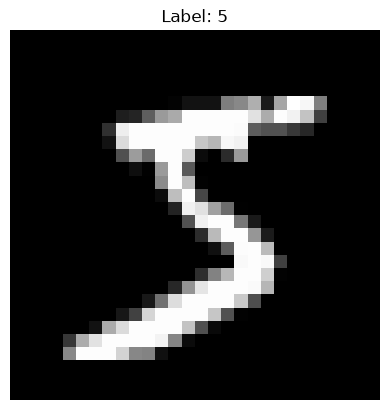

In [3]:
plt.imshow(X_train[0], cmap='gray')
plt.title(f'Label: {y_train[0]}')
plt.axis('off')
plt.show()

### Preprocessing

In [4]:
# Normalisasi pixel dari 0-255 menjai 0-1
X_train = X_train /255.0
X_test = X_test/255.0

# Tambahkan channel
# Dari (60000, 28, 28)
# Menjadi (60000, 28, 28, 1)

X_train = X_train.reshape(-1,28,28,1)
X_test = X_test.reshape(-1,28,28,1)

print("Setelah preprocessing:")
print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)

Setelah preprocessing:
X_train : (60000, 28, 28, 1)
X_test  : (10000, 28, 28, 1)


model CNN

In [5]:
model = Sequential([Conv2D(32, (3,3), activation='relu', input_shape=(28,28,1)),
                    MaxPooling2D((2,2)),
                    Conv2D(64,(3,3),activation='relu'),
                    MaxPooling2D((3,3,)),
                    Flatten(),
                    Dense(128,activation='relu'),
                    Dense(10, activation='softmax')])
model.summary()

c:\Users\MyBook Hype\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 3, 3, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,962 (367.04 KB)

 Trainable params: 93,962 (367.04 KB)

 Non-trainable params: 0 (0.00 B)

Compile

In [6]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

Training

In [7]:
history = model.fit(X_train, y_train, epochs=5,batch_size=128,validation_split=0.2)

Epoch 1/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 38s 63ms/step - accuracy: 0.9082 - loss: 0.3113 - val_accuracy: 0.9733 - val_loss: 0.0924
Epoch 2/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 40s 62ms/step - accuracy: 0.9753 - loss: 0.0805 - val_accuracy: 0.9812 - val_loss: 0.0682
Epoch 3/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 32s 86ms/step - accuracy: 0.9819 - loss: 0.0584 - val_accuracy: 0.9851 - val_loss: 0.0522
Epoch 4/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 36s 73ms/step - accuracy: 0.9855 - loss: 0.0473 - val_accuracy: 0.9861 - val_loss: 0.0508
Epoch 5/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 42s 73ms/step - accuracy: 0.9879 - loss: 0.0386 - val_accuracy: 0.9859 - val_loss: 0.0530


Evaluasi

In [8]:
train_loss, train_accuracy = model.evaluate(X_train,y_train)
print('Train Loss :',train_loss)
print('Train Accuracy', train_accuracy)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 29s 15ms/step - accuracy: 0.9879 - loss: 0.0393
Train Loss : 0.03933093324303627
Train Accuracy 0.9878833293914795


In [9]:
test_loss, test_accuracy = model.evaluate(X_test,y_test)
print('Test Loss :',test_loss)
print('Test Acuracy', test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.9863 - loss: 0.0420
Test Loss : 0.042021580040454865
Test Acuracy 0.986299991607666


Prediksi

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step   
Label sebenarnya : 7
Hasil Prediksi   : 7


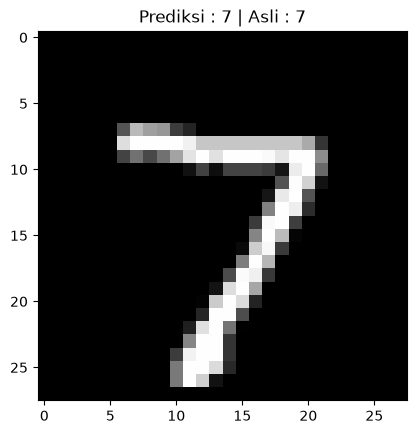

In [10]:
index = 0

gambar = X_test[index]

prediksi = model.predict(np.expand_dims(gambar,axis=0))

hasil = np.argmax(prediksi)

print('Label sebenarnya :', y_test[index])
print('Hasil Prediksi   :',hasil)

plt.imshow(gambar.squeeze(), cmap='gray')
plt.title(f'Prediksi : {hasil} | Asli : {y_test[index]}')
plt.axis()
plt.show()